In [2]:
import os, time, math, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score

os.makedirs("figures", exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

D_MODEL = 128
SEEDS = [42, 123, 999]
RESULTS_PATH = "../results.csv"

CSV_COLS = [
    "problem", "model", "seed", "seq_len", "test_acc", "macro_f1",
    "test_mse", "params", "sec_per_epoch", "val_loss_nats", "bits_per_char", "notes"
]

def log_result(row_dict):
    df_new = pd.DataFrame([{c: row_dict.get(c, "") for c in CSV_COLS}])
    if os.path.exists(RESULTS_PATH):
        df_old = pd.read_csv(RESULTS_PATH)
        df = pd.concat([df_old, df_new], ignore_index=True)
    else:
        df = df_new
    df.to_csv(RESULTS_PATH, index=False)

def set_seed(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

Using device: cuda


In [3]:
def scaled_dot_product_attention(Q, K, V, mask=None):
    # Q: (B, ..., L_q, d_k), K: (B, ..., L_k, d_k), V: (B, ..., L_k, d_v)
    d_k = Q.size(-1)
    scores = torch.matmul(Q, K.transpose(-2, -1)) / math.sqrt(d_k)  # (B, ..., L_q, L_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    attn_weights = torch.softmax(scores, dim=-1)  # (B, ..., L_q, L_k)
    output = torch.matmul(attn_weights, V)        # (B, ..., L_q, d_v)
    return output, attn_weights

# Unit tests for Task 1
torch.manual_seed(0)
Q_t = torch.randn(2, 4, 10, 16)
K_t = torch.randn(2, 4, 10, 16)
V_t = torch.randn(2, 4, 10, 16)
out_my, w_my = scaled_dot_product_attention(Q_t, K_t, V_t)
out_ref = F.scaled_dot_product_attention(Q_t, K_t, V_t)

assert torch.allclose(w_my.sum(dim=-1), torch.ones_like(w_my.sum(dim=-1)), atol=1e-5), "Weights must sum to 1"
assert torch.allclose(out_my, out_ref, atol=1e-5), "Must match F.scaled_dot_product_attention"

causal_mask = torch.tril(torch.ones(10, 10, dtype=torch.bool))
_, w_causal = scaled_dot_product_attention(Q_t, K_t, V_t, mask=causal_mask)
upper_tri = torch.triu(torch.ones(10, 10, dtype=torch.bool), diagonal=1)
assert torch.all(w_causal[..., upper_tri] == 0.0), "Future weights must be zero under causal mask"

# Verify 3-token hand-worked example
Q_hand = torch.tensor([[1., 0.], [0., 1.], [1., 1.]])
K_hand = torch.tensor([[1., 0.], [0., 1.], [1., 0.]])
V_hand = torch.tensor([[1., 2.], [3., 4.], [5., 6.]])
out_hand, w_hand = scaled_dot_product_attention(Q_hand, K_hand, V_hand)
assert torch.allclose(out_hand, torch.tensor([[3., 4.], [3., 4.], [3., 4.]]), atol=1e-4)
print("Task 1 Attention unit tests & 3-token hand example verified! Output:\n", out_hand)

class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=2048):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float32) * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))  # (1, max_len, d_model)

    def forward(self, x):
        return x + self.pe[:, :x.size(1), :]

class MyMultiHeadAttention(nn.Module):
    def __init__(self, d_model, num_heads, dropout=0.1):
        super().__init__()
        assert d_model % num_heads == 0
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads

        self.W_Q = nn.Linear(d_model, d_model)
        self.W_K = nn.Linear(d_model, d_model)
        self.W_V = nn.Linear(d_model, d_model)
        self.W_O = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        B, L, D = x.shape
        # Project and reshape to (B, num_heads, L, d_k)
        Q = self.W_Q(x).view(B, L, self.num_heads, self.d_k).transpose(1, 2)
        K = self.W_K(x).view(B, L, self.num_heads, self.d_k).transpose(1, 2)
        V = self.W_V(x).view(B, L, self.num_heads, self.d_k).transpose(1, 2)

        attn_out, attn_weights = scaled_dot_product_attention(Q, K, V, mask=mask)
        # Concatenate heads back to (B, L, D)
        concat = attn_out.transpose(1, 2).contiguous().view(B, L, D)
        return self.W_O(self.drop(concat)), attn_weights

class PreLNEncoderBlock(nn.Module):
    def __init__(self, d_model, num_heads, d_ff=None, dropout=0.1):
        super().__init__()
        d_ff = d_ff or 4 * d_model
        self.ln1 = nn.LayerNorm(d_model)
        self.mha = MyMultiHeadAttention(d_model, num_heads, dropout=dropout)
        self.drop1 = nn.Dropout(dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.ffn = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(d_ff, d_model)
        )
        self.drop2 = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        h, attn_w = self.mha(self.ln1(x), mask=mask)
        x = x + self.drop1(h)
        x = x + self.drop2(self.ffn(self.ln2(x)))
        return x, attn_w

# Verify parameter count derivation for d=128, d_ff=512
blk = PreLNEncoderBlock(128, 4, 512)
weight_params = sum(p.numel() for n, p in blk.named_parameters() if "weight" in n and "ln" not in n)
total_params = sum(p.numel() for p in blk.parameters())
assert weight_params == 4 * (128**2) + 2 * 128 * 512 == 196608
assert total_params == 196608 + (4 * 128 + 512 + 128) + (4 * 128) == 198272
print(f"Encoder block weights={weight_params}, total with biases & LayerNorm={total_params}")

Task 1 Attention unit tests & 3-token hand example verified! Output:
 tensor([[3.0000, 4.0000],
        [3.0000, 4.0000],
        [3.0000, 4.0000]])
Encoder block weights=196608, total with biases & LayerNorm=198272


In [4]:
def load_har_for_p2():
    p1_path = "../problem1/UCI HAR Dataset"
    base_path = p1_path if os.path.exists(p1_path) else "UCI HAR Dataset"
    if not os.path.exists(base_path):
        url = "https://archive.ics.uci.edu/static/public/240/human+activity+recognition+using+smartphones.zip"
        urllib.request.urlretrieve(url, "har.zip")
        with zipfile.ZipFile("har.zip", "r") as zf:
            zf.extractall("har_temp")
        inner_zip = os.path.join("har_temp", "UCI HAR Dataset.zip")
        if os.path.exists(inner_zip):
            with zipfile.ZipFile(inner_zip, "r") as zf:
                zf.extractall(".")
        base_path = "UCI HAR Dataset"

    signals = [
        "body_acc_x", "body_acc_y", "body_acc_z",
        "body_gyro_x", "body_gyro_y", "body_gyro_z",
        "total_acc_x", "total_acc_y", "total_acc_z"
    ]
    def read_split(split):
        data = [np.loadtxt(f"{base_path}/{split}/Inertial Signals/{s}_{split}.txt", dtype=np.float32) for s in signals]
        X = np.stack(data, axis=-1)
        y = np.loadtxt(f"{base_path}/{split}/y_{split}.txt", dtype=np.int64) - 1
        subj = np.loadtxt(f"{base_path}/{split}/subject_{split}.txt", dtype=np.int64)
        return X, y, subj
    return read_split("train"), read_split("test")

(X_tr_raw, y_tr_raw, subj_tr), (X_te_raw, y_te_raw, _) = load_har_for_p2()

class HARTransformerClassifier(nn.Module):
    def __init__(self, d_model=128, num_heads=4, num_layers=2, pos_type="sinusoidal", patch_size=8):
        super().__init__()
        self.patch_size = patch_size
        num_patches = 128 // patch_size  # 16 patches
        self.patch_proj = nn.Linear(9 * patch_size, d_model)
        self.cls_token = nn.Parameter(torch.randn(1, 1, d_model) * 0.02)
        self.pos_type = pos_type
        if pos_type == "sinusoidal":
            self.pos_enc = SinusoidalPositionalEncoding(d_model, max_len=num_patches + 1)
        elif pos_type == "learned":
            self.pos_emb = nn.Parameter(torch.randn(1, num_patches + 1, d_model) * 0.02)
        self.blocks = nn.ModuleList([PreLNEncoderBlock(d_model, num_heads, 4 * d_model, dropout=0.1) for _ in range(num_layers)])
        self.norm = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 6)

    def forward(self, x):
        B, T, C = x.shape
        x = x.view(B, T // self.patch_size, C * self.patch_size)  # (B, 16, 72)
        x = self.patch_proj(x)
        cls = self.cls_token.expand(B, -1, -1)
        x = torch.cat([cls, x], dim=1)  # (B, 17, D)
        if self.pos_type == "sinusoidal":
            x = self.pos_enc(x)
        elif self.pos_type == "learned":
            x = x + self.pos_emb
        for blk in self.blocks:
            x, _ = blk(x)
        return self.head(self.norm(x[:, 0]))

def run_har_transformer(pos_type, seed, epochs=25):
    set_seed(seed)
    val_subjs = np.random.default_rng(seed).choice(np.unique(subj_tr), 4, replace=False)
    val_mask = np.isin(subj_tr, val_subjs)
    X_tr, y_tr = X_tr_raw[~val_mask], y_tr_raw[~val_mask]
    X_va, y_va = X_tr_raw[val_mask], y_tr_raw[val_mask]
    mean, std = X_tr.mean((0, 1), keepdims=True), X_tr.std((0, 1), keepdims=True) + 1e-8
    X_tr, X_va, X_te = (X_tr - mean)/std, (X_va - mean)/std, (X_te_raw - mean)/std

    tr_loader = DataLoader(TensorDataset(torch.tensor(X_tr), torch.tensor(y_tr)), batch_size=128, shuffle=True)
    va_loader = DataLoader(TensorDataset(torch.tensor(X_va), torch.tensor(y_va)), batch_size=128)
    te_loader = DataLoader(TensorDataset(torch.tensor(X_te), torch.tensor(y_te_raw)), batch_size=128)

    model = HARTransformerClassifier(D_MODEL, 4, 2, pos_type=pos_type).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    best_acc, best_st, ep_times = -1.0, None, []

    for _ in range(epochs):
        t0 = time.time()
        model.train()
        for xb, yb in tr_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
        ep_times.append(time.time() - t0)

        model.eval()
        preds, targs = [], []
        with torch.no_grad():
            for xb, yb in va_loader:
                preds.append(model(xb.to(DEVICE)).argmax(-1).cpu()); targs.append(yb)
        vacc = accuracy_score(torch.cat(targs), torch.cat(preds))
        if vacc > best_acc:
            best_acc = vacc
            best_st = {k: v.cpu().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_st)
    model.eval()
    preds, targs = [], []
    with torch.no_grad():
        for xb, yb in te_loader:
            preds.append(model(xb.to(DEVICE)).argmax(-1).cpu()); targs.append(yb)
    acc = accuracy_score(torch.cat(targs), torch.cat(preds))
    f1 = f1_score(torch.cat(targs), torch.cat(preds), average="macro")
    return acc, f1, sum(p.numel() for p in model.parameters()), float(np.mean(ep_times))

for pos in ["none", "sinusoidal", "learned"]:
    accs, f1s = [], []
    for s in SEEDS:
        acc, f1, params, sec_ep = run_har_transformer(pos, s)
        accs.append(acc); f1s.append(f1)
        log_result({
            "problem": "P2_TaskA_HAR", "model": f"Transformer_{pos}", "seed": s, "seq_len": 128,
            "test_acc": round(acc, 4), "macro_f1": round(f1, 4),
            "params": params, "sec_per_epoch": round(sec_ep, 4), "notes": f"d={D_MODEL}, pos={pos}"
        })
    print(f"HAR Transformer ({pos}): Acc={np.mean(accs):.4f}±{np.std(accs):.4f}, F1={np.mean(f1s):.4f}±{np.std(f1s):.4f}, Params={params}")

HAR Transformer (none): Acc=0.9112±0.0103, F1=0.9109±0.0107, Params=407046
HAR Transformer (sinusoidal): Acc=0.9105±0.0056, F1=0.9106±0.0057, Params=407046
HAR Transformer (learned): Acc=0.9282±0.0159, F1=0.9283±0.0165, Params=409222


Main Char LM -> Val Loss: 1.5746 nats | BPC: 2.2716


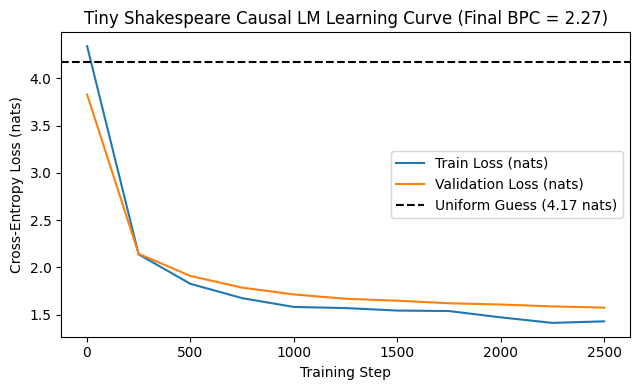


--- Temp 0.2 (first 180 chars) ---
KING RICHARD:
No, sir, the shall be so be so the constance.

QUEEN ELIZABETH:
So more than the seat and than and the world
Than the prince of the country of the seems,
And the stat...

--- Temp 0.8 (first 180 chars) ---
KING RICHARD:
Sir, it gracious with man.

First Citizen:
Even for the life of myself, and see with your son.

LUCIO:
My lord o' this rage is her pity
And what they are in my body i...

--- Temp 1.5 (first 180 chars) ---
KING RICHARD:
Pity unformard, ins my just livineaw gatle,
Never a left assicianing.
A whence fit time but oals, friam that live
Will upon my lack to know your fiet, less by mock.
C...


In [5]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
text = urllib.request.urlopen(url).read().decode("utf-8")
chars = sorted(list(set(text)))
vocab_size = len(chars)
assert vocab_size == 65
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for i, ch in enumerate(chars)}

data_ids = torch.tensor([stoi[c] for c in text], dtype=torch.long)
split_idx = int(0.9 * len(data_ids))
train_data = data_ids[:split_idx]
val_data = data_ids[split_idx:]

class CharCausalTransformer(nn.Module):
    def __init__(self, vocab_size=65, d_model=128, num_heads=4, num_layers=4, max_len=512, causal=True):
        super().__init__()
        self.causal = causal
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_enc = SinusoidalPositionalEncoding(d_model, max_len=max_len)
        self.blocks = nn.ModuleList([PreLNEncoderBlock(d_model, num_heads, 4 * d_model, dropout=0.1) for _ in range(num_layers)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)

    def forward(self, idx):
        B, L = idx.shape
        x = self.pos_enc(self.tok_emb(idx))
        mask = torch.tril(torch.ones(L, L, dtype=torch.bool, device=idx.device)) if self.causal else None
        attn_maps = []
        for blk in self.blocks:
            x, aw = blk(x, mask=mask)
            attn_maps.append(aw)
        return self.head(self.ln_f(x)), attn_maps

@torch.no_grad()
def generate_text(model, prompt_str, max_new_tokens=500, temperature=0.8, top_k=20, context_len=128):
    model.eval()
    idx = torch.tensor([[stoi[c] for c in prompt_str]], dtype=torch.long, device=DEVICE)
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_len:]
        logits, _ = model(idx_cond)
        logits = logits[:, -1, :] / temperature
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = -float("inf")
        probs = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probs, num_samples=1)
        idx = torch.cat((idx, idx_next), dim=1)
    return "".join([itos[i] for i in idx[0].tolist()])

def train_char_lm(num_heads=4, num_layers=4, context_len=128, causal=True, steps=2500, seed=42):
    set_seed(seed)
    model = CharCausalTransformer(vocab_size, D_MODEL, num_heads, num_layers, max_len=512, causal=causal).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
    batch_size = 64

    def get_batch(split_tensor):
        ix = torch.randint(len(split_tensor) - context_len - 1, (batch_size,))
        x = torch.stack([split_tensor[i:i+context_len] for i in ix]).to(DEVICE)
        y = torch.stack([split_tensor[i+1:i+context_len+1] for i in ix]).to(DEVICE)
        return x, y

    tr_losses, va_losses, eval_steps = [], [], []
    t0 = time.time()
    for step in range(1, steps + 1):
        model.train()
        xb, yb = get_batch(train_data)
        logits, _ = model(xb)
        loss = F.cross_entropy(logits.view(-1, vocab_size), yb.view(-1))
        opt.zero_grad()
        loss.backward()
        opt.step()

        if step % 250 == 0 or step == 1:
            model.eval()
            with torch.no_grad():
                v_losses = []
                for _ in range(20):
                    vx, vy = get_batch(val_data)
                    v_logits, _ = model(vx)
                    v_losses.append(F.cross_entropy(v_logits.view(-1, vocab_size), vy.view(-1)).item())
                va_loss = float(np.mean(v_losses))
            tr_losses.append(loss.item())
            va_losses.append(va_loss)
            eval_steps.append(step)

    elapsed = time.time() - t0
    final_val_nats = va_losses[-1]
    bpc = final_val_nats / math.log(2)
    return model, eval_steps, tr_losses, va_losses, final_val_nats, bpc, elapsed

lm_model, eval_steps, tr_curve, va_curve, val_nats, bpc, elapsed = train_char_lm(num_heads=4, num_layers=4, context_len=128, causal=True, steps=2500)
print(f"Main Char LM -> Val Loss: {val_nats:.4f} nats | BPC: {bpc:.4f}")
log_result({
    "problem": "P2_TaskB_CharLM", "model": "CausalTransformer_4H_4L", "seed": 42, "seq_len": 128,
    "params": sum(p.numel() for p in lm_model.parameters()), "sec_per_epoch": round(elapsed / 10, 4),
    "val_loss_nats": round(val_nats, 4), "bits_per_char": round(bpc, 4), "notes": "d=128, 2500 steps"
})

# Plot Task B Learning Curve
plt.figure(figsize=(6.5, 4))
plt.plot(eval_steps, tr_curve, label="Train Loss (nats)")
plt.plot(eval_steps, va_curve, label="Validation Loss (nats)")
plt.axhline(math.log(65), color="k", linestyle="--", label="Uniform Guess (4.17 nats)")
plt.xlabel("Training Step")
plt.ylabel("Cross-Entropy Loss (nats)")
plt.title(f"Tiny Shakespeare Causal LM Learning Curve (Final BPC = {bpc:.2f})")
plt.legend()
plt.tight_layout()
plt.savefig("figures/shakespeare_learning_curve.png", dpi=200)
plt.show()

# Generate 500 chars at temperatures 0.2, 0.8, 1.5 and save to generated_samples.txt
with open("generated_samples.txt", "w", encoding="utf-8") as f:
    for temp in [0.2, 0.8, 1.5]:
        sample = generate_text(lm_model, "KING RICHARD:\n", max_new_tokens=500, temperature=temp, top_k=20)
        f.write(f"=== TEMPERATURE {temp} ===\n{sample}\n\n")
        print(f"\n--- Temp {temp} (first 180 chars) ---\n{sample[:180]}...")

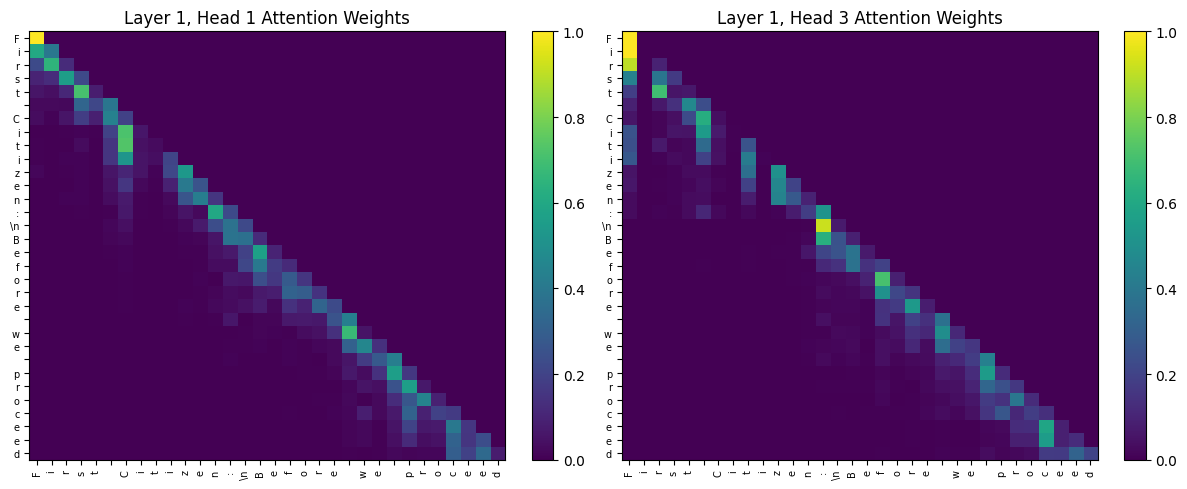

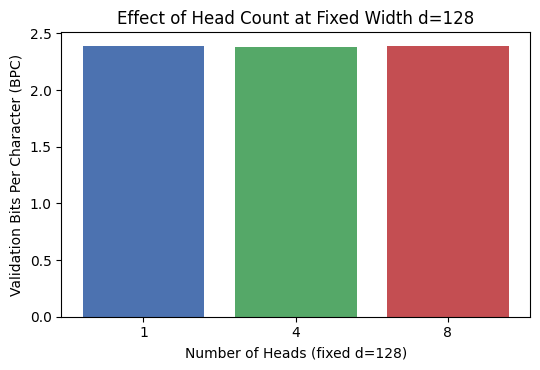

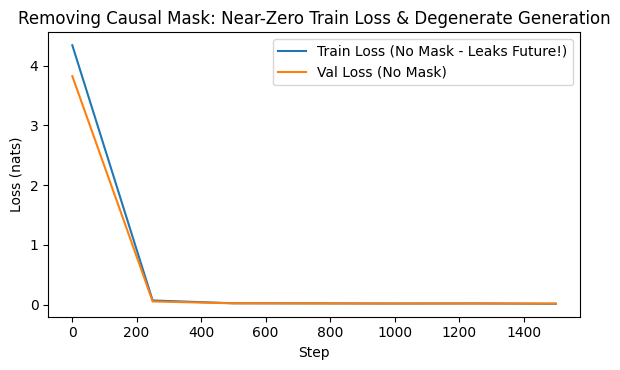

No-mask generation sample: 'KING RICHARD:\n\n\n\n\n\n\n\n\n\n\n\n\nFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFFF'


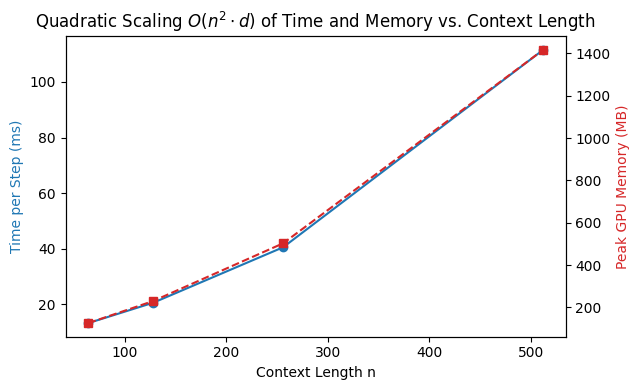

In [6]:
# 5(a) Attention heatmaps of two heads on one sentence
sample_sent = "First Citizen:\nBefore we proceed any further, hear me speak."
inp_ids = torch.tensor([[stoi[c] for c in sample_sent[:32]]], device=DEVICE)
lm_model.eval()
with torch.no_grad():
    _, attn_maps = lm_model(inp_ids)
# Layer 0, Head 0 and Head 2
tokens = [repr(c)[1:-1] for c in sample_sent[:32]]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for idx, h_id in enumerate([0, 2]):
    mat = attn_maps[0][0, h_id].cpu().numpy()
    im = axes[idx].imshow(mat, cmap="viridis", aspect="auto")
    axes[idx].set_xticks(range(len(tokens))); axes[idx].set_xticklabels(tokens, rotation=90, fontsize=7)
    axes[idx].set_yticks(range(len(tokens))); axes[idx].set_yticklabels(tokens, fontsize=7)
    axes[idx].set_title(f"Layer 1, Head {h_id + 1} Attention Weights")
    plt.colorbar(im, ax=axes[idx], fraction=0.046)
plt.tight_layout()
plt.savefig("figures/attention_heatmaps.png", dpi=200)
plt.show()

# 5(b) Heads = 1, 4, 8 at fixed d = 128
head_results = []
for nh in [1, 4, 8]:
    _, _, _, _, v_nats, v_bpc, t_sec = train_char_lm(num_heads=nh, num_layers=4, context_len=128, causal=True, steps=1500)
    head_results.append({"heads": nh, "val_nats": v_nats, "bpc": v_bpc, "time": t_sec})
    log_result({
        "problem": "P2_Ablation_Heads", "model": f"Transformer_H={nh}", "seed": 42, "seq_len": 128,
        "val_loss_nats": round(v_nats, 4), "bits_per_char": round(v_bpc, 4), "notes": f"d=128, heads={nh}"
    })
df_heads = pd.DataFrame(head_results)
plt.figure(figsize=(5.5, 3.8))
plt.bar([str(h) for h in df_heads["heads"]], df_heads["bpc"], color=["#4c72b0", "#55a868", "#c44e52"])
plt.xlabel("Number of Heads (fixed d=128)")
plt.ylabel("Validation Bits Per Character (BPC)")
plt.title("Effect of Head Count at Fixed Width d=128")
plt.tight_layout()
plt.savefig("figures/ablation_heads.png", dpi=200)
plt.show()

# 5(c) Remove causal mask and show training loss & generation collapse
nomask_model, nm_steps, nm_tr, nm_va, nm_nats, nm_bpc, _ = train_char_lm(num_heads=4, num_layers=4, context_len=128, causal=False, steps=1500)
log_result({
    "problem": "P2_Ablation_NoMask", "model": "Transformer_NoMask", "seed": 42, "seq_len": 128,
    "val_loss_nats": round(nm_nats, 4), "bits_per_char": round(nm_bpc, 4), "notes": "Future token leakage"
})
plt.figure(figsize=(6, 3.8))
plt.plot(nm_steps, nm_tr, label="Train Loss (No Mask - Leaks Future!)")
plt.plot(nm_steps, nm_va, label="Val Loss (No Mask)")
plt.xlabel("Step")
plt.ylabel("Loss (nats)")
plt.title("Removing Causal Mask: Near-Zero Train Loss & Degenerate Generation")
plt.legend()
plt.tight_layout()
plt.savefig("figures/ablation_nomask.png", dpi=200)
plt.show()
print("No-mask generation sample:", repr(generate_text(nomask_model, "KING RICHARD:\n", max_new_tokens=120, temperature=0.8)))

# 5(d) Time and peak GPU memory at context 64, 128, 256, 512 (O(n^2 * d))
ctx_lengths = [64, 128, 256, 512]
times_ms, mems_mb = [], []
bench_model = CharCausalTransformer(vocab_size, D_MODEL, 4, 4, max_len=512, causal=True).to(DEVICE)
opt_b = torch.optim.AdamW(bench_model.parameters(), lr=1e-3)

for ctx in ctx_lengths:
    xb = torch.randint(0, vocab_size, (32, ctx), device=DEVICE)
    yb = torch.randint(0, vocab_size, (32, ctx), device=DEVICE)
    # Warmup
    for _ in range(3):
        logits, _ = bench_model(xb)
        F.cross_entropy(logits.view(-1, vocab_size), yb.view(-1)).backward()
        opt_b.zero_grad()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    for _ in range(15):
        logits, _ = bench_model(xb)
        loss = F.cross_entropy(logits.view(-1, vocab_size), yb.view(-1))
        loss.backward()
        opt_b.step()
        opt_b.zero_grad()
    if torch.cuda.is_available():
        torch.cuda.synchronize()
        peak_mb = torch.cuda.max_memory_allocated() / (1024 ** 2)
    else:
        peak_mb = 0.0
    times_ms.append((time.time() - t0) / 15 * 1000)
    mems_mb.append(peak_mb)

fig, ax1 = plt.subplots(figsize=(6.5, 4))
ax1.plot(ctx_lengths, times_ms, "o-", color="tab:blue", label="Step Time (ms)")
ax1.set_xlabel("Context Length n")
ax1.set_ylabel("Time per Step (ms)", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(ctx_lengths, mems_mb, "s--", color="tab:red", label="Peak GPU Memory (MB)")
ax2.set_ylabel("Peak GPU Memory (MB)", color="tab:red")
plt.title(r"Quadratic Scaling $O(n^2 \cdot d)$ of Time and Memory vs. Context Length")
fig.tight_layout()
plt.savefig("figures/context_scaling.png", dpi=200)
plt.show()